# TRUSTSR Lab 04.03 — Coverage-Signal Robustness

**Phase:** Lab 04 — Recovery-policy evaluation  
**Status:** Synthetic simulation | Version 1.0.0

## Motivation
Lab 04.02's threshold policy reduced false negatives in the generated scenarios, but its synthetic coverage signal was calculated using the simulator's true incident-edge counts. That makes the signal more informed than a real deployment may be.

This lab tests whether conclusions persist when the policy receives only observable proxy signals, with controllable noise and missingness. The hidden ground-truth graph is used only by the evaluator.

## Research question
How sensitive are false negatives, unnecessary quarantines, and clean-work preservation to the quality of an observable-only coverage proxy?

## Signal and policy definitions
- **Observed degree proxy:** number of observed incident edges, normalized by the maximum observed degree in that trial. This uses observed edges only; it is not a calibrated probability of telemetry completeness.
- **Noisy proxy:** observed degree proxy plus zero-mean bounded synthetic noise, clipped to [0, 1].
- **Observed reachability:** quarantine nodes reachable from known compromised sources in the observed graph.
- **Threshold abstention:** quarantine observed-reachable nodes and nodes whose noisy proxy is below a threshold.
- **Full quarantine:** quarantine every node as a safety-first reference.

The observed-degree proxy can be misleading: a node with few observed dependencies may be genuinely low-degree or may have missing edges. This ambiguity is the point of the experiment.

## Evidence boundary
All graphs, missing edges, proxy values, and outcomes are synthetic. Results are conditional on these assumptions and do not establish real-world security, calibration, or recovery effectiveness.

## 1. Configuration

In [1]:
import random, sys, platform
from collections import defaultdict, deque
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261013
N_TRIALS = 250
N_NODES = 50
EDGE_PROBABILITY = 0.06
MISSING_EDGE_RATES = [0.0, 0.1, 0.25, 0.4]
NOISE_LEVELS = [0.0, 0.10, 0.25, 0.40]
THRESHOLDS = [0.20, 0.35, 0.50, 0.65]
N_COMPROMISED_SOURCES = 2

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic simulation only")
print({"seed": SEED, "trials": N_TRIALS, "nodes": N_NODES,
       "missing_edge_rates": MISSING_EDGE_RATES, "noise_levels": NOISE_LEVELS,
       "thresholds": THRESHOLDS})

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
Execution UTC: 2026-10-11T10:26:44.214401+00:00
Evidence classification: synthetic simulation only
{'seed': 20261013, 'trials': 250, 'nodes': 50, 'missing_edge_rates': [0.0, 0.1, 0.25, 0.4], 'noise_levels': [0.0, 0.1, 0.25, 0.4], 'thresholds': [0.2, 0.35, 0.5, 0.65]}


## 2. Graph, observable proxy, and scoring helpers

In [2]:
def make_dag(rng, n_nodes, edge_probability):
    nodes = [f"S{i:02d}" for i in range(n_nodes)]
    edges = [(nodes[i], nodes[j]) for i in range(n_nodes) for j in range(i+1, n_nodes)
             if rng.random() < edge_probability]
    return nodes, edges

def reachable(nodes, edges, sources):
    adj = defaultdict(list)
    for u, v in edges:
        adj[u].append(v)
    seen, queue = set(sources), deque(sources)
    while queue:
        u = queue.popleft()
        for v in adj[u]:
            if v not in seen:
                seen.add(v)
                queue.append(v)
    return seen

def observe_edges(rng, edges, missing_rate):
    observed, hidden = [], []
    for edge in edges:
        (hidden if rng.random() < missing_rate else observed).append(edge)
    return observed, hidden

def observed_degree_proxy(nodes, observed_edges, rng, noise_level):
    degree = {n: 0 for n in nodes}
    for u, v in observed_edges:
        degree[u] += 1
        degree[v] += 1
    max_degree = max(degree.values()) if degree else 1
    if max_degree == 0:
        max_degree = 1
    raw = {n: degree[n] / max_degree for n in nodes}
    noisy = {n: min(1.0, max(0.0, raw[n] + rng.uniform(-noise_level, noise_level))
                   ) for n in nodes}
    return raw, noisy

def score(nodes, truth, quarantined):
    clean = set(nodes) - set(truth)
    fn = set(truth) - set(quarantined)
    fp = clean & set(quarantined)
    preserved = clean - set(quarantined)
    return {
        "truth_contaminated": len(truth), "truth_clean": len(clean),
        "quarantined": len(quarantined), "false_negatives": len(fn),
        "false_negative_rate": len(fn) / len(truth) if truth else 0.0,
        "false_positives": len(fp),
        "false_positive_rate": len(fp) / len(clean) if clean else 0.0,
        "clean_preservation_rate": len(preserved) / len(clean) if clean else 0.0,
        "quarantine_blast_radius": len(quarantined) / len(nodes)
    }

print("Helpers defined.")

Helpers defined.


## 3. Run paired synthetic trials

In [3]:
trial_rows, node_rows = [], []
for missing_rate in MISSING_EDGE_RATES:
    for trial in range(N_TRIALS):
        trial_seed = SEED + int(missing_rate * 10000) * 1000 + trial
        graph_rng = random.Random(trial_seed)
        nodes, true_edges = make_dag(graph_rng, N_NODES, EDGE_PROBABILITY)
        sources = set(graph_rng.sample(nodes[:max(3, N_NODES // 4)], N_COMPROMISED_SOURCES))
        truth = reachable(nodes, true_edges, sources)
        observed_edges, hidden_edges = observe_edges(graph_rng, true_edges, missing_rate)
        observed_pred = reachable(nodes, observed_edges, sources)

        for noise_level in NOISE_LEVELS:
            proxy_rng = random.Random(trial_seed + int(noise_level * 1000) + 4242)
            raw_proxy, noisy_proxy = observed_degree_proxy(nodes, observed_edges, proxy_rng, noise_level)
            policy_predictions = {
                "full_quarantine": set(nodes),
                "observed_reachability": set(observed_pred)
            }
            for threshold in THRESHOLDS:
                quarantined = set(observed_pred) | {
                    n for n in nodes if noisy_proxy[n] < threshold
                }
                policy_predictions[f"threshold_{threshold:.2f}"] = quarantined

            for policy, quarantined in policy_predictions.items():
                metric_row = score(nodes, truth, quarantined)
                threshold = float(policy.split("_")[1]) if policy.startswith("threshold_") else None
                trial_rows.append({
                    "missing_edge_rate": missing_rate, "noise_level": noise_level,
                    "trial": trial, "policy": policy, "threshold": threshold,
                    "node_count": len(nodes), "true_edge_count": len(true_edges),
                    "observed_edge_count": len(observed_edges),
                    "hidden_edge_count": len(hidden_edges),
                    "compromised_sources": ";".join(sorted(sources)), **metric_row
                })
                for node in nodes:
                    confirmed = node in observed_pred
                    low_proxy = node not in observed_pred and policy.startswith("threshold_") and node in quarantined
                    if policy == "full_quarantine" and not confirmed:
                        label = "quarantined_by_full_quarantine"
                    elif confirmed:
                        label = "confirmed_contaminated_by_observed_graph"
                    elif low_proxy:
                        label = "potentially_contaminated_low_observed_degree_proxy"
                    elif node in quarantined:
                        label = "quarantined_by_policy"
                    else:
                        label = "not_flagged_by_policy"
                    node_rows.append({
                        "missing_edge_rate": missing_rate, "noise_level": noise_level,
                        "trial": trial, "policy": policy, "node": node,
                        "observed_degree_proxy": raw_proxy[node],
                        "noisy_proxy": noisy_proxy[node],
                        "ground_truth_contaminated": node in truth,
                        "quarantined": node in quarantined, "policy_label": label
                    })

trial_df = pd.DataFrame(trial_rows)
node_df = pd.DataFrame(node_rows)
expected_rows = len(MISSING_EDGE_RATES) * N_TRIALS * len(NOISE_LEVELS) * (2 + len(THRESHOLDS))
assert len(trial_df) == expected_rows
assert len(node_df) == expected_rows * N_NODES
assert trial_df["false_negative_rate"].between(0, 1).all()
assert trial_df["false_positive_rate"].between(0, 1).all()
assert node_df["observed_degree_proxy"].between(0, 1).all()
assert node_df["noisy_proxy"].between(0, 1).all()
print("Policy evaluations:", len(trial_df))
print("Node-level rows:", len(node_df))
print("Structure and range assertions passed.")
display(trial_df.head())

Policy evaluations: 24000
Node-level rows: 1200000
Structure and range assertions passed.


   missing_edge_rate  noise_level  trial                 policy  threshold  node_count  true_edge_count  observed_edge_count  hidden_edge_count compromised_sources  truth_contaminated  truth_clean  \
0                0.0          0.0      0        full_quarantine        NaN          50               74                   74                  0             S07;S10                   7           43   
1                0.0          0.0      0  observed_reachability        NaN          50               74                   74                  0             S07;S10                   7           43   
2                0.0          0.0      0         threshold_0.20       0.20          50               74                   74                  0             S07;S10                   7           43   
3                0.0          0.0      0         threshold_0.35       0.35          50               74                   74                  0             S07;S10                   7           43   


## 4. Aggregate results and verify policy invariants

In [4]:
METRICS = ["false_negative_rate", "false_positive_rate", "clean_preservation_rate",
           "quarantine_blast_radius", "false_negatives", "false_positives", "quarantined"]
aggregate_df = trial_df.groupby(["missing_edge_rate", "noise_level", "policy"])[METRICS].agg(
    ["mean", "std"]).reset_index()
aggregate_df.columns = [
    "_".join(str(x) for x in col if str(x) != "").rstrip("_")
    if isinstance(col, tuple) else col for col in aggregate_df.columns
]
display(aggregate_df)

# In each paired scenario, adding a threshold rule cannot reduce quarantine size.
for (missing_rate, noise_level, trial), sub in trial_df.groupby(
        ["missing_edge_rate", "noise_level", "trial"]):
    q = sub.set_index("policy")["quarantined"]
    assert q["threshold_0.65"] >= q["threshold_0.50"] >= q["threshold_0.35"] >= q["threshold_0.20"]
    assert q["full_quarantine"] == N_NODES

# With no omitted edges, observed reachability equals synthetic ground truth.
complete = trial_df[(trial_df["missing_edge_rate"] == 0.0) &
                    (trial_df["policy"] == "observed_reachability")]
assert (complete["false_negatives"] == 0).all()
print("Threshold monotonicity and complete-graph assertions passed.")

    missing_edge_rate  noise_level                 policy  false_negative_rate_mean  false_negative_rate_std  false_positive_rate_mean  false_positive_rate_std  clean_preservation_rate_mean  \
0                 0.0          0.0        full_quarantine                  0.000000                 0.000000                  1.000000                 0.000000                      0.000000   
1                 0.0          0.0  observed_reachability                  0.000000                 0.000000                  0.000000                 0.000000                      1.000000   
2                 0.0          0.0         threshold_0.20                  0.000000                 0.000000                  0.245155                 0.097511                      0.754845   
3                 0.0          0.0         threshold_0.35                  0.000000                 0.000000                  0.522955                 0.138294                      0.477045   
4                 0.0          0.0 

Threshold monotonicity and complete-graph assertions passed.


## 5. Plot robustness across missing-edge and noise conditions

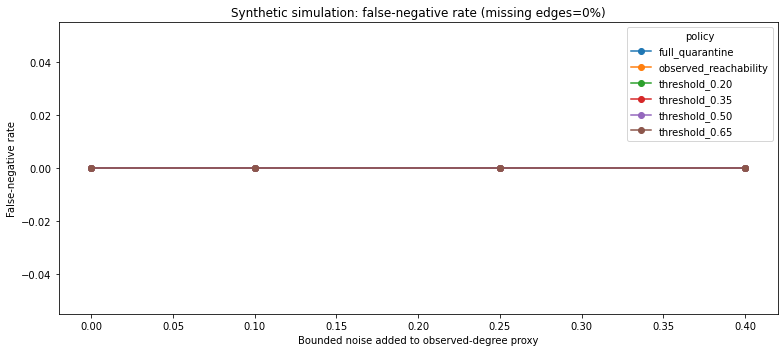

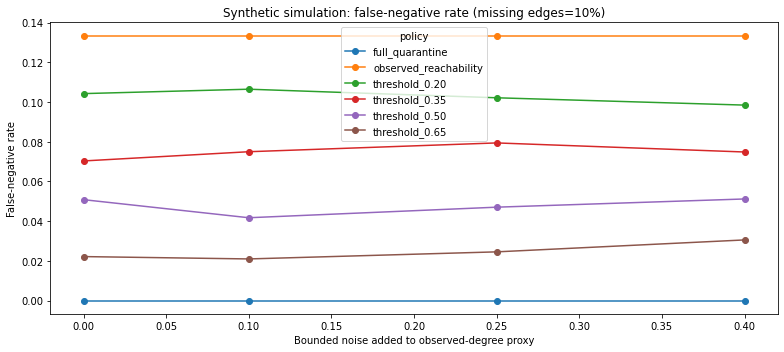

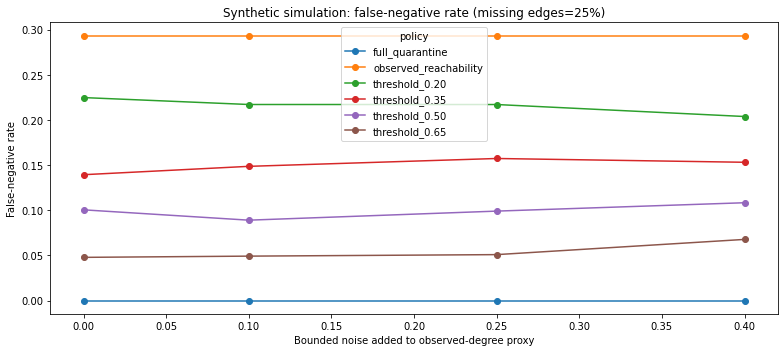

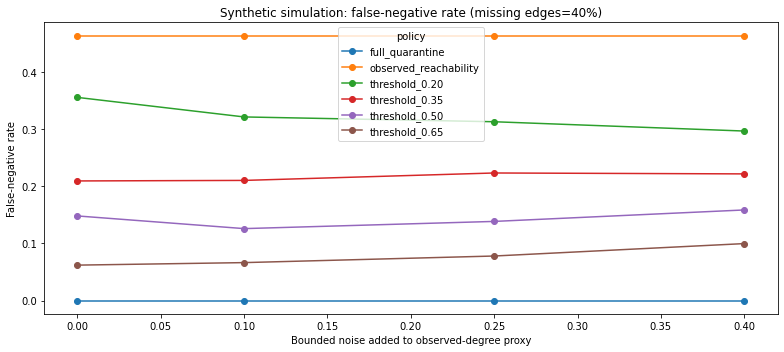

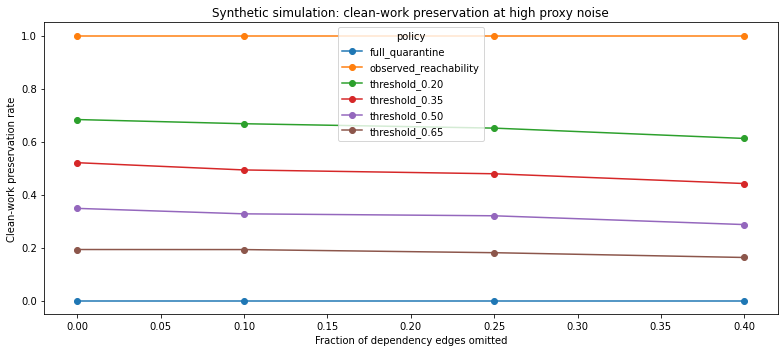

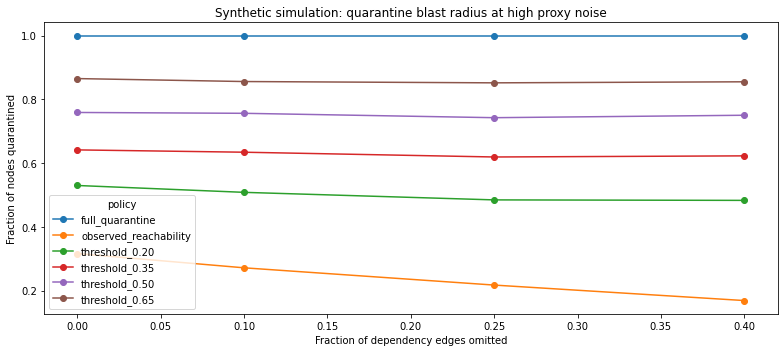

In [5]:
# One plot per missing-edge condition: compare false-negative rate as proxy noise changes.
for missing_rate in MISSING_EDGE_RATES:
    subset = trial_df[trial_df["missing_edge_rate"] == missing_rate]
    pivot = subset.groupby(["noise_level", "policy"])["false_negative_rate"].mean().unstack("policy")
    ax = pivot.plot(marker="o", figsize=(11, 5))
    ax.set_title(f"Synthetic simulation: false-negative rate (missing edges={missing_rate:.0%})")
    ax.set_xlabel("Bounded noise added to observed-degree proxy")
    ax.set_ylabel("False-negative rate")
    plt.tight_layout()
    plt.show()

# Operational trade-off at the highest configured noise level.
high_noise = trial_df[trial_df["noise_level"] == max(NOISE_LEVELS)]
for metric, title, ylabel in [
    ("clean_preservation_rate", "Synthetic simulation: clean-work preservation at high proxy noise",
     "Clean-work preservation rate"),
    ("quarantine_blast_radius", "Synthetic simulation: quarantine blast radius at high proxy noise",
     "Fraction of nodes quarantined")
]:
    pivot = high_noise.groupby(["missing_edge_rate", "policy"])[metric].mean().unstack("policy")
    ax = pivot.plot(marker="o", figsize=(11, 5))
    ax.set_title(title)
    ax.set_xlabel("Fraction of dependency edges omitted")
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()

## 6. Measured synthetic findings — no assumed winner

In [6]:
summary_df = trial_df.groupby(["missing_edge_rate", "noise_level", "policy"])[
    ["false_negative_rate", "false_positive_rate", "clean_preservation_rate", "quarantine_blast_radius"]
].mean().reset_index()
display(summary_df)

# Compact comparison: observed reachability versus each threshold at each condition.
for missing_rate in MISSING_EDGE_RATES:
    for noise_level in NOISE_LEVELS:
        sub = summary_df[(summary_df["missing_edge_rate"] == missing_rate) &
                         (summary_df["noise_level"] == noise_level)].set_index("policy")
        baseline = sub.loc["observed_reachability"]
        print(f"Missing={missing_rate:.0%}, proxy noise={noise_level:.2f}: "
              f"observed reachability FN={baseline['false_negative_rate']:.3f}, "
              f"preservation={baseline['clean_preservation_rate']:.3f}, "
              f"blast={baseline['quarantine_blast_radius']:.3f}")
        for threshold in THRESHOLDS:
            row = sub.loc[f"threshold_{threshold:.2f}"]
            print(f"  threshold {threshold:.2f}: FN={row['false_negative_rate']:.3f}, "
                  f"FP={row['false_positive_rate']:.3f}, "
                  f"preservation={row['clean_preservation_rate']:.3f}, "
                  f"blast={row['quarantine_blast_radius']:.3f}")

print("All outputs above are synthetic simulation; interpret measured trade-offs, not a presumed winner.")

    missing_edge_rate  noise_level                 policy  false_negative_rate  false_positive_rate  clean_preservation_rate  quarantine_blast_radius
0                 0.0          0.0        full_quarantine             0.000000             1.000000                 0.000000                  1.00000
1                 0.0          0.0  observed_reachability             0.000000             0.000000                 1.000000                  0.31624
2                 0.0          0.0         threshold_0.20             0.000000             0.245155                 0.754845                  0.48024
3                 0.0          0.0         threshold_0.35             0.000000             0.522955                 0.477045                  0.66984
4                 0.0          0.0         threshold_0.50             0.000000             0.679699                 0.320301                  0.77584
..                ...          ...                    ...                  ...                  ... 

Missing=0%, proxy noise=0.00: observed reachability FN=0.000, preservation=1.000, blast=0.316
  threshold 0.20: FN=0.000, FP=0.245, preservation=0.755, blast=0.480
  threshold 0.35: FN=0.000, FP=0.523, preservation=0.477, blast=0.670
  threshold 0.50: FN=0.000, FP=0.680, preservation=0.320, blast=0.776
  threshold 0.65: FN=0.000, FP=0.863, preservation=0.137, blast=0.903
Missing=0%, proxy noise=0.10: observed reachability FN=0.000, preservation=1.000, blast=0.316
  threshold 0.20: FN=0.000, FP=0.239, preservation=0.761, blast=0.476
  threshold 0.35: FN=0.000, FP=0.498, preservation=0.502, blast=0.652
  threshold 0.50: FN=0.000, FP=0.723, preservation=0.277, blast=0.806
  threshold 0.65: FN=0.000, FP=0.871, preservation=0.129, blast=0.908
Missing=0%, proxy noise=0.25: observed reachability FN=0.000, preservation=1.000, blast=0.316
  threshold 0.20: FN=0.000, FP=0.271, preservation=0.729, blast=0.498
  threshold 0.35: FN=0.000, FP=0.490, preservation=0.510, blast=0.647
  threshold 0.50: 

## 7. Export reproducibility artifacts

In [7]:
trial_df.to_csv("trustsr_lab04_03_trial_results.csv", index=False)
node_df.to_csv("trustsr_lab04_03_node_classifications.csv", index=False)
aggregate_df.to_csv("trustsr_lab04_03_aggregate_metrics.csv", index=False)
summary_df.to_csv("trustsr_lab04_03_policy_summary.csv", index=False)

print("CSV exports created:")
for filename in [
    "trustsr_lab04_03_trial_results.csv",
    "trustsr_lab04_03_node_classifications.csv",
    "trustsr_lab04_03_aggregate_metrics.csv",
    "trustsr_lab04_03_policy_summary.csv"
]:
    print("-", filename)
print("Evidence classification: synthetic simulation only.")

CSV exports created:
- trustsr_lab04_03_trial_results.csv
- trustsr_lab04_03_node_classifications.csv
- trustsr_lab04_03_aggregate_metrics.csv
- trustsr_lab04_03_policy_summary.csv
Evidence classification: synthetic simulation only.


## 8. Interpretation and limitations

- The observed-degree proxy is a crude observable-only signal, not a probability that a node's dependencies are fully known.
- A low observed degree can mean genuinely few dependencies or missing telemetry; the policy cannot distinguish those explanations from this signal alone.
- The noise model is synthetic and bounded; real telemetry errors may be biased, correlated, delayed, or adversarial.
- The simulator's ground truth is used only for scoring and to construct the synthetic missing-edge process. It is not supplied to the policy.
- A threshold can reduce false negatives while increasing false positives and quarantine blast radius. Report all metrics together.
- No real agent, memory store, tool call, incident, or external side effect is tested.

**Suggested paper wording:** “We evaluated threshold-based abstention using a synthetic observed-degree proxy under controlled edge omission and bounded noise. Results are conditional on the graph generator and proxy-noise model and do not establish production effectiveness or security guarantees.”

## Completion criteria
1. Run all cells from a fresh Colab runtime.
2. Confirm assertions pass.
3. Inspect all four plots and CSV exports.
4. Report any errors or unexpected patterns before advancing to Lab 04.04.